=== A iniciar Optuna Tuning no Kaggle (GPU (CUDA)) ===
Resultados guardados na pasta: /kaggle/working/optuna_results



  0%|          | 0/25 [00:00<?, ?it/s]

Trial #0 | Época 1/5:   0%|          | 0/320 [00:00<?, ?it/s]

Trial #0 | Época 2/5:   0%|          | 0/320 [00:00<?, ?it/s]

Trial #0 | Época 3/5:   0%|          | 0/320 [00:00<?, ?it/s]

Trial #0 | Época 4/5:   0%|          | 0/320 [00:00<?, ?it/s]

... (149 outputs left out)

Trial #24 | Época 5/5:   0%|          | 0/320 [00:00<?, ?it/s]


RESUMO DOS RESULTADOS DA OTIMIZAÇÃO
Total de Trials tentados: 25
Trials concluídos com sucesso: 20

Melhor Trial: #24
Melhor Loss Obtida: 0.16134

Melhores Hiperparâmetros Encontrados:
  - lr: 2.7641832368009826e-05
  - optimizer: Adam
  - weight_decay: 9.935449124387662e-05
  - anchor_scales: medium
  - rpn_nms_thresh: 0.5017305625552403


/tmp/ipykernel_859/150993321.py:376: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  fig_history = plot_optimization_history(study)
/tmp/ipykernel_859/150993321.py:379: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  fig_importance = plot_param_importances(study)



[Sucesso] Gráficos de análise guardados em: /kaggle/working/optuna_results


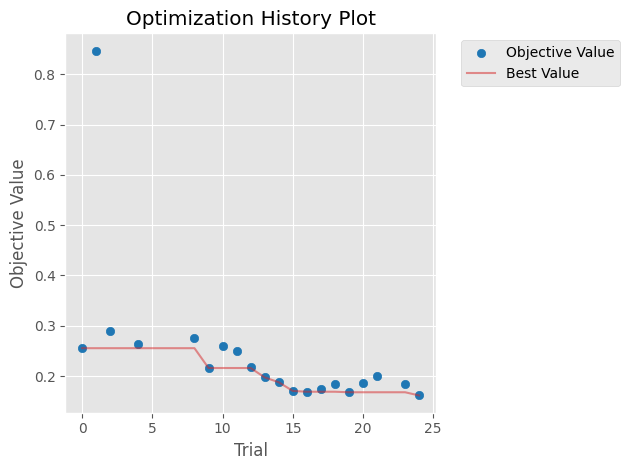

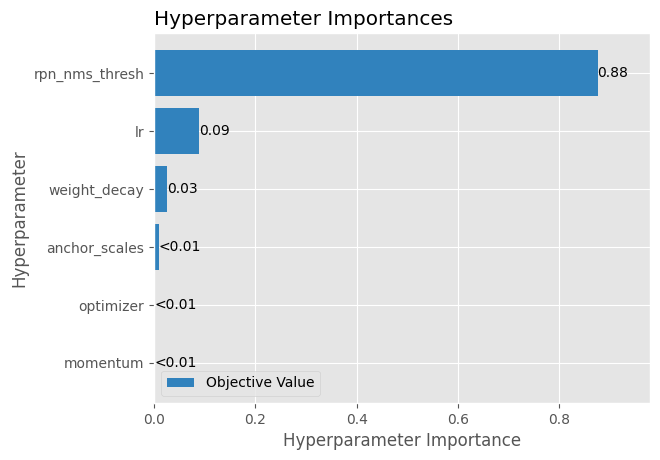

In [ ]:
import os
import cv2
import sys
import torch
import optuna
import random
import logging
import traceback
import numpy as np
import matplotlib.pyplot as plt
import torchvision
from pathlib import Path
from tqdm.auto import tqdm
from collections import defaultdict
from torch.utils.data import Dataset, DataLoader
from torchvision.models.detection import FasterRCNN
from torchvision.models.detection.rpn import AnchorGenerator
from optuna.visualization.matplotlib import plot_optimization_history, plot_param_importances

optuna.logging.set_verbosity(optuna.logging.WARNING)


DATASET_DIR = Path('/kaggle/input/datasets/marinheirobusiness/faceaia/dataset')

WIDER_TRAIN_DIR = DATASET_DIR / "WIDER_train" / "WIDER_train" / "images"
WIDER_ANNO = DATASET_DIR / "wider_face_split" / "wider_face_split" / "wider_face_train_bbx_gt.txt"

OUTPUT_DIR = Path("/kaggle/working/optuna_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

logging.basicConfig(
    filename=OUTPUT_DIR / "optuna_execution.log",
    level=logging.INFO,
    format="%(asctime)s [%(levelname)s] %(message)s"
)

def parse_annotations(anno_path):
    dataset_records = []
    if not os.path.exists(anno_path):
        raise FileNotFoundError(f"Ficheiro de anotação não encontrado em: {anno_path}")
        
    with open(anno_path, 'r') as f:
        lines = f.readlines()
        
    i = 0
    while i < len(lines):
        img_rel_path = lines[i].strip()
        i += 1
        num_faces = int(lines[i].strip())
        i += 1
        
        boxes = []
        if num_faces == 0:
            i += 1
        else:
            for _ in range(num_faces):
                parts = lines[i].strip().split()
                x, y, w, h = map(int, parts[:4])
                if w > 0 and h > 0:
                    boxes.append((x, y, w, h))
                i += 1
                
        dataset_records.append({
            'img_path': img_rel_path,
            'boxes': boxes
        })
        
    return dataset_records

def get_stratified_sample(all_records, total_samples=300):
    """
    Garante que as 300 imagens retiram uma quota equilibrada de cada pasta
    de evento do WIDER FACE para cobrir todos os níveis de complexidade.
    """
    folder_buckets = defaultdict(list)
    for rec in all_records:
        folder_name = Path(rec['img_path']).parts[0]
        folder_buckets[folder_name].append(rec)
    
    num_folders = len(folder_buckets)
    samples_per_folder = max(1, total_samples // num_folders)
    
    stratified_records = []
    
    for folder_name, items in folder_buckets.items():
        random.seed(42)  # Seed fixa para consistência em todas as trials
        n_to_sample = min(samples_per_folder, len(items))
        stratified_records.extend(random.sample(items, n_to_sample))
        
    if len(stratified_records) < total_samples:
        remaining_needed = total_samples - len(stratified_records)
        used_set = set(id(r) for r in stratified_records)
        remaining_pool = [r for r in all_records if id(r) not in used_set]
        random.seed(42)
        stratified_records.extend(random.sample(remaining_pool, min(remaining_needed, len(remaining_pool))))
        
    return stratified_records[:total_samples]

class WiderFaceDataset(Dataset):
    def __init__(self, records, img_dir):
        self.records = records
        self.img_dir = img_dir

    def __getitem__(self, idx):
        sample = self.records[idx]
        img_path = str(self.img_dir / sample['img_path'])

        image = cv2.imread(img_path)
        if image is None:
            raise FileNotFoundError(f"Imagem não encontrada: {img_path}")

        if len(image.shape) == 2:
            image = cv2.cvtColor(image, cv2.COLOR_GRAY2BGR)

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        height, width = image.shape[:2]

        image = torch.from_numpy(
            image.astype(np.float32) / 255.0
        ).permute(2, 0, 1)

        valid_boxes = []
        for x, y, w, h in sample['boxes']:
            x1 = max(0.0, min(float(x), float(width)))
            y1 = max(0.0, min(float(y), float(height)))
            x2 = max(0.0, min(float(x + w), float(width)))
            y2 = max(0.0, min(float(y + h), float(height)))

            if (x2 - x1) >= 1.0 and (y2 - y1) >= 1.0:
                valid_boxes.append([x1, y1, x2, y2])

        if len(valid_boxes) == 0:
            boxes = torch.zeros((0, 4), dtype=torch.float32)
            labels = torch.zeros((0,), dtype=torch.int64)
        else:
            boxes = torch.tensor(valid_boxes, dtype=torch.float32)
            labels = torch.ones((len(boxes),), dtype=torch.int64)

        target = {
            "boxes": boxes,
            "labels": labels
        }

        return image, target

    def __len__(self):
        return len(self.records)

def collate_fn(batch):
    return tuple(zip(*batch))


def create_model(trial):
    vgg = torchvision.models.vgg16(weights=torchvision.models.VGG16_Weights.DEFAULT)
    backbone = vgg.features
    backbone.out_channels = 512

    anchor_options = {
        "small": ((8, 16, 32, 64, 128),),
        "medium": ((16, 32, 64, 128, 256),),
        "wide": ((8, 16, 32, 64, 128, 256),)
    }

    anchor_key = trial.suggest_categorical("anchor_scales", ["small", "medium", "wide"])
    anchor_scales = anchor_options[anchor_key]

    anchor_generator = AnchorGenerator(
        sizes=anchor_scales,
        aspect_ratios=((0.5, 1.0, 2.0),)
    )

    roi_pooler = torchvision.ops.MultiScaleRoIAlign(
        featmap_names=['0'],
        output_size=7,
        sampling_ratio=2
    )

    rpn_nms_thresh = trial.suggest_float("rpn_nms_thresh", 0.5, 0.8)

    model = FasterRCNN(
        backbone,
        num_classes=2,
        rpn_anchor_generator=anchor_generator,
        box_roi_pool=roi_pooler,
        rpn_nms_thresh=rpn_nms_thresh,
        rpn_post_nms_top_n_train=1000
    )
    
    return model

def objective(trial):
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    BATCH_SIZE = 2  

    lr = trial.suggest_float("lr", 1e-5, 3e-3, log=True)
    optimizer_name = trial.suggest_categorical("optimizer", ["Adam", "SGD"])
    weight_decay = trial.suggest_float("weight_decay", 1e-5, 1e-3, log=True)

    try:
        model = create_model(trial).to(device)

        if optimizer_name == "Adam":
            optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
        else:
            momentum = trial.suggest_float("momentum", 0.85, 0.95)
            optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=momentum, weight_decay=weight_decay)

        all_records = parse_annotations(WIDER_ANNO)
        records = get_stratified_sample(all_records, total_samples=640)
        
        dataset = WiderFaceDataset(records, WIDER_TRAIN_DIR)
        
        dataloader = DataLoader(
            dataset, 
            batch_size=BATCH_SIZE, 
            shuffle=True, 
            collate_fn=collate_fn, 
            num_workers=2, 
            pin_memory=True if torch.cuda.is_available() else False
        )

        EPOCHS = 5  
        PATIENCE = 3
        best_loss = float('inf')
        epochs_no_improve = 0
        epoch_losses = []

        for epoch in range(EPOCHS):
            model.train()
            running_loss = 0.0
            
            pbar = tqdm(
                dataloader, 
                desc=f"Trial #{trial.number} | Época {epoch+1}/{EPOCHS}", 
                leave=False
            )
            
            for images, targets in pbar:
                images = list(image.to(device) for image in images)
                targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

                loss_dict = model(images, targets)
                losses = sum(loss for loss in loss_dict.values())

                if not torch.isfinite(losses):
                    raise ValueError("Loss NaN/Inf detetada.")

                optimizer.zero_grad()
                losses.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=10.0)
                optimizer.step()
                
                running_loss += losses.item()
                pbar.set_postfix(loss=f"{losses.item():.4f}")
                
            avg_loss = running_loss / len(dataloader)
            epoch_losses.append(avg_loss)
            trial.report(avg_loss, epoch)

            if trial.should_prune():
                raise optuna.exceptions.TrialPruned()

            if avg_loss < best_loss:
                best_loss = avg_loss
                epochs_no_improve = 0
            else:
                epochs_no_improve += 1
                if epochs_no_improve >= PATIENCE:
                    break

        plt.figure()
        plt.plot(range(1, len(epoch_losses) + 1), epoch_losses, marker='o')
        plt.title(f'Training Loss - Trial {trial.number}')
        plt.xlabel('Épocas')
        plt.ylabel('Loss')
        plt.savefig(OUTPUT_DIR / f'loss_trial_{trial.number}.png', dpi=150)
        plt.close()

        del model
        torch.cuda.empty_cache()

        return best_loss

    except torch.cuda.OutOfMemoryError:
        print(f"\n[VRAM Esgotada] Trial {trial.number} atingiu o limite da GPU. A limpar VRAM...")
        if 'model' in locals():
            del model
        torch.cuda.empty_cache()
        raise optuna.exceptions.TrialPruned()

    except optuna.exceptions.TrialPruned:
        if 'model' in locals():
            del model
        torch.cuda.empty_cache()
        raise

    except Exception as e:
        print(f"\n[Erro na Trial {trial.number}] Erro: {e}. A passar à próxima...")
        logging.error(f"Trial {trial.number} falhou: {traceback.format_exc()}")
        if 'model' in locals():
            del model
        torch.cuda.empty_cache()
        raise optuna.exceptions.TrialPruned()


if __name__ == "__main__":
    device_name = "GPU (CUDA)" if torch.cuda.is_available() else "CPU"
    print(f"=== A iniciar Optuna Tuning no Kaggle ({device_name}) ===")
    print(f"Resultados guardados na pasta: {OUTPUT_DIR.resolve()}\n")
    
    db_path = OUTPUT_DIR / "optuna_kaggle_clean.db"
    
    if db_path.exists():
        db_path.unlink()

    storage_url = f"sqlite:///{db_path.absolute()}"

    study = optuna.create_study(
        study_name="widerface_vgg16_kaggle",
        storage=storage_url,
        load_if_exists=False,
        direction="minimize",
        pruner=optuna.pruners.MedianPruner(
            n_startup_trials=3,
            n_warmup_steps=1
        )
    )
    
    try:
        study.optimize(objective, n_trials=25, show_progress_bar=True)
    except KeyboardInterrupt:
        print("\n[Interrupção] Treino parado manualmente pelo utilizador.")

    print("\n==========================================")
    print("RESUMO DOS RESULTADOS DA OTIMIZAÇÃO")
    print("==========================================")
    print(f"Total de Trials tentados: {len(study.trials)}")
    
    completed_trials = [t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE]
    print(f"Trials concluídos com sucesso: {len(completed_trials)}")
    
    if len(completed_trials) > 0 and study.best_trial:
        print(f"\nMelhor Trial: #{study.best_trial.number}")
        print(f"Melhor Loss Obtida: {study.best_value:.5f}")
        print("\nMelhores Hiperparâmetros Encontrados:")
        for k, v in study.best_trial.params.items():
            print(f"  - {k}: {v}")

        try:
            fig_history = plot_optimization_history(study)
            fig_history.figure.savefig(OUTPUT_DIR / 'optuna_optimization_history.png', dpi=300, bbox_inches='tight')

            fig_importance = plot_param_importances(study)
            fig_importance.figure.savefig(OUTPUT_DIR / 'optuna_param_importances.png', dpi=300, bbox_inches='tight')
            print(f"\n[Sucesso] Gráficos de análise guardados em: {OUTPUT_DIR.resolve()}")
        except Exception as e:
            print(f"Não foi possível gerar os gráficos finais: {e}")